In [1]:
from gwosc import datasets
from matplotlib import mlab
from gwosc.datasets import find_datasets
from gwosc.datasets import event_gps
from scipy.interpolate import interp1d
from scipy.signal import butter, filtfilt
from gwpy.timeseries import TimeSeries
import numpy as np
import matplotlib.pyplot as plt
import os
import scipy
import scipy.signal
import scipy.interpolate

/home/gopal/miniconda3/envs/gwenv/lib/python3.10/site-packages/gwpy/time/__init__.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(True)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS


In [2]:
tevent = event_gps('GW150914')
print(tevent)
duration = 104  # seconds
# Put GW150914 approximately at the center of the 104-second test window
start_time = tevent - duration/2
end_time   = tevent + duration/2

print("Start:", start_time)
print("End:", end_time)
print("Duration:", end_time - start_time, "seconds")

1126259462.4
Start: 1126259410.4
End: 1126259514.4
Duration: 104.0 seconds


In [3]:
segment = (int(tevent) - 52, int(tevent) +  52)
H1_data = TimeSeries.fetch_open_data('H1', *segment, verbose=True, cache=True)
L1_data = TimeSeries.fetch_open_data('L1', *segment, verbose=True, cache=True)

Fetched 1 URLs from gwosc.org for [1126259410 .. 1126259514))
Reading data... [Done]
Fetched 1 URLs from gwosc.org for [1126259410 .. 1126259514))
Reading data... [Done]


In [4]:
# GPS time arrays
time_H1_gps = np.asarray(H1_data.times.value).copy()
time_L1_gps = np.asarray(L1_data.times.value).copy()

# strain arrays
strain_H1 = np.asarray(H1_data.value).copy()
strain_L1 = np.asarray(L1_data.value).copy()

# Sampling information
fs = float(H1_data.sample_rate.value)
dt = 1.0 / fs

# GW150914 event GPS time
tevent = float(event_gps("GW150914"))

# Time relative to the event
time_relative = time_H1_gps - tevent

print("fs =", fs)
print("dt =", dt)
print("Time range relative to event:", time_relative[0], "to", time_relative[-1], "s")

fs = 4096.0
dt = 0.000244140625
Time range relative to event: -52.40000009536743 to 51.59975576400757 s


In [5]:
NFFT = int(1 * fs)
Pxx_H1, freqs_H1 = mlab.psd(strain_H1, Fs=fs, NFFT=NFFT)
Pxx_L1, freqs_L1 = mlab.psd(strain_L1, Fs=fs, NFFT=NFFT)
psd_H1 = interp1d(freqs_H1, Pxx_H1)
psd_L1 = interp1d(freqs_L1, Pxx_L1)

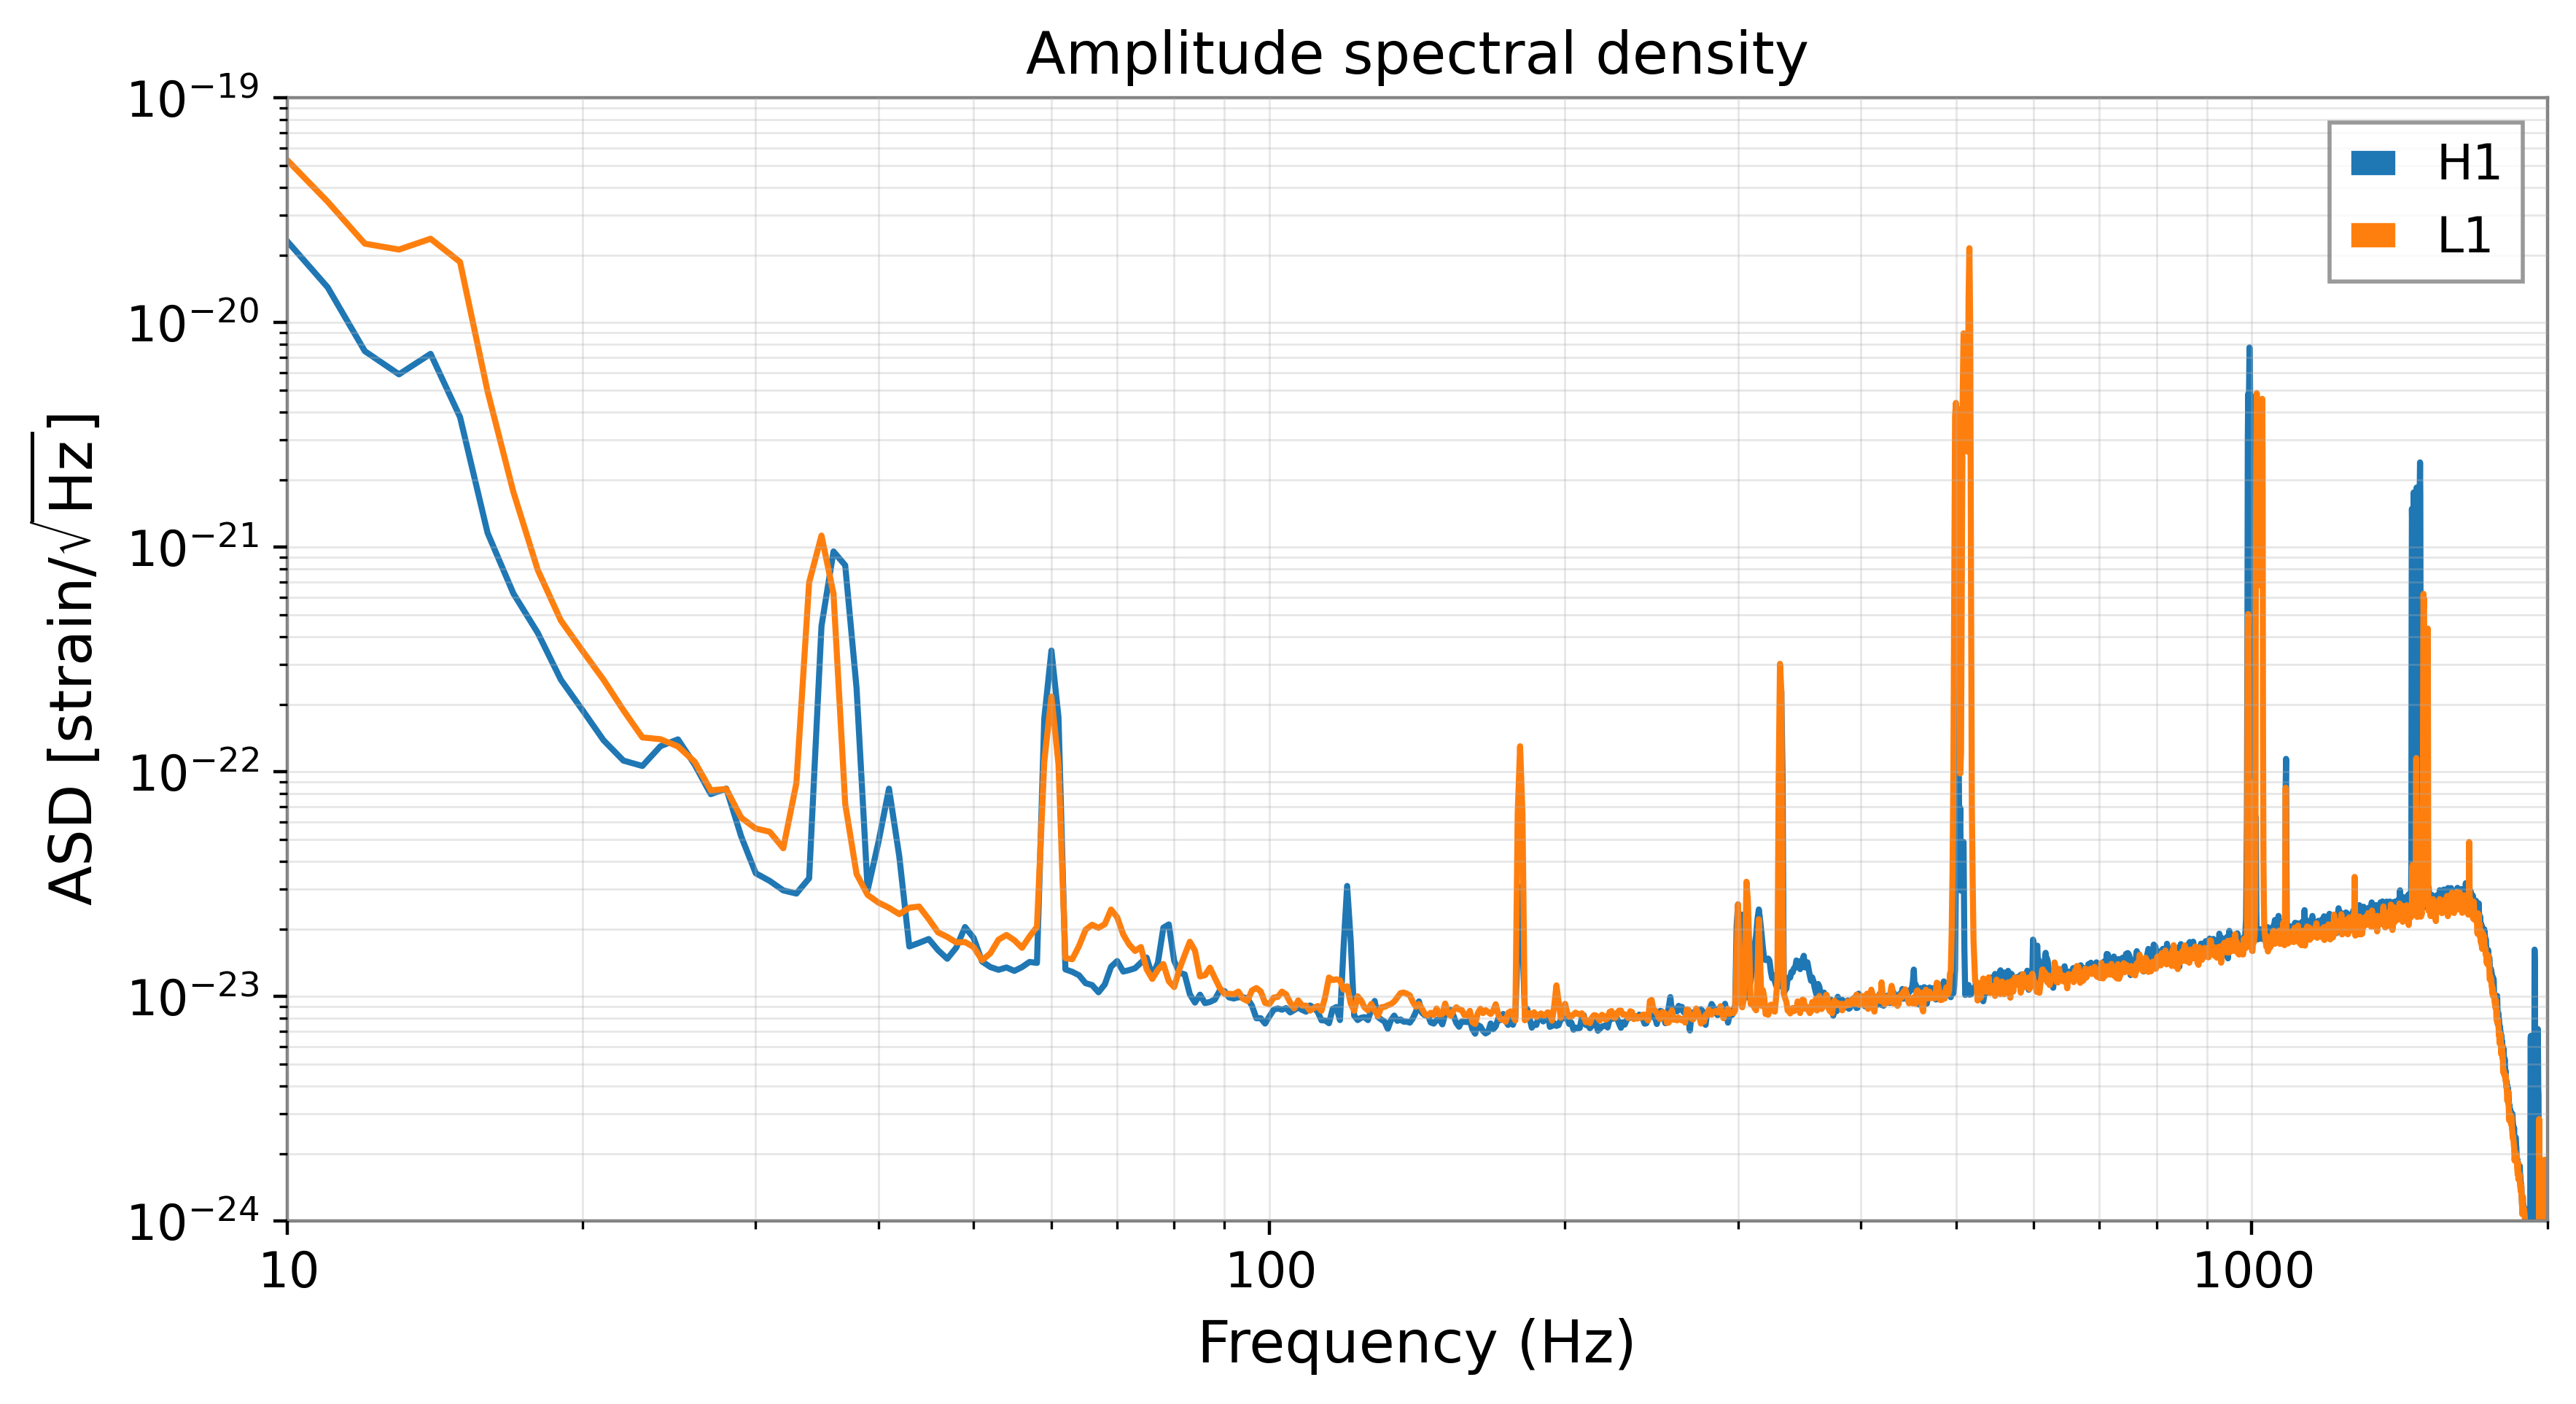

In [6]:
plt.figure(figsize=(10, 5), dpi = 400)
plt.loglog(freqs_H1, np.sqrt(Pxx_H1), label="H1")
plt.loglog(freqs_L1, np.sqrt(Pxx_L1), label="L1")
plt.xlim(10, 2000)
plt.ylim(1e-24, 1e-19)
plt.xlabel("Frequency (Hz)")
plt.ylabel(r"ASD [strain/$\sqrt{\mathrm{Hz}}$]")
plt.title("Amplitude spectral density")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

In [7]:
def whiten(strain, interp_psd, dt):
    """
    Whitening convention used in the GWOSC GW150914 tutorial.
    """
    Nt = len(strain)
    freqs = np.fft.rfftfreq(Nt, dt)
    hf = np.fft.rfft(strain)
    white_hf = hf / np.sqrt(interp_psd(freqs) / dt / 2.0)
    white_ht = np.fft.irfft( white_hf, n=Nt)

    return white_ht

In [8]:
strain_H1_whiten = whiten(strain_H1, psd_H1, dt)
strain_L1_whiten = whiten(strain_L1, psd_L1, dt)

In [9]:
bb, ab = butter(
    4,
    [
        20.0 * 2.0 / fs,
        300.0 * 2.0 / fs
    ],
    btype="band"
)

strain_H1_whitenbp = filtfilt(bb, ab, strain_H1_whiten)
strain_L1_whitenbp = filtfilt(bb, ab,  strain_L1_whiten)

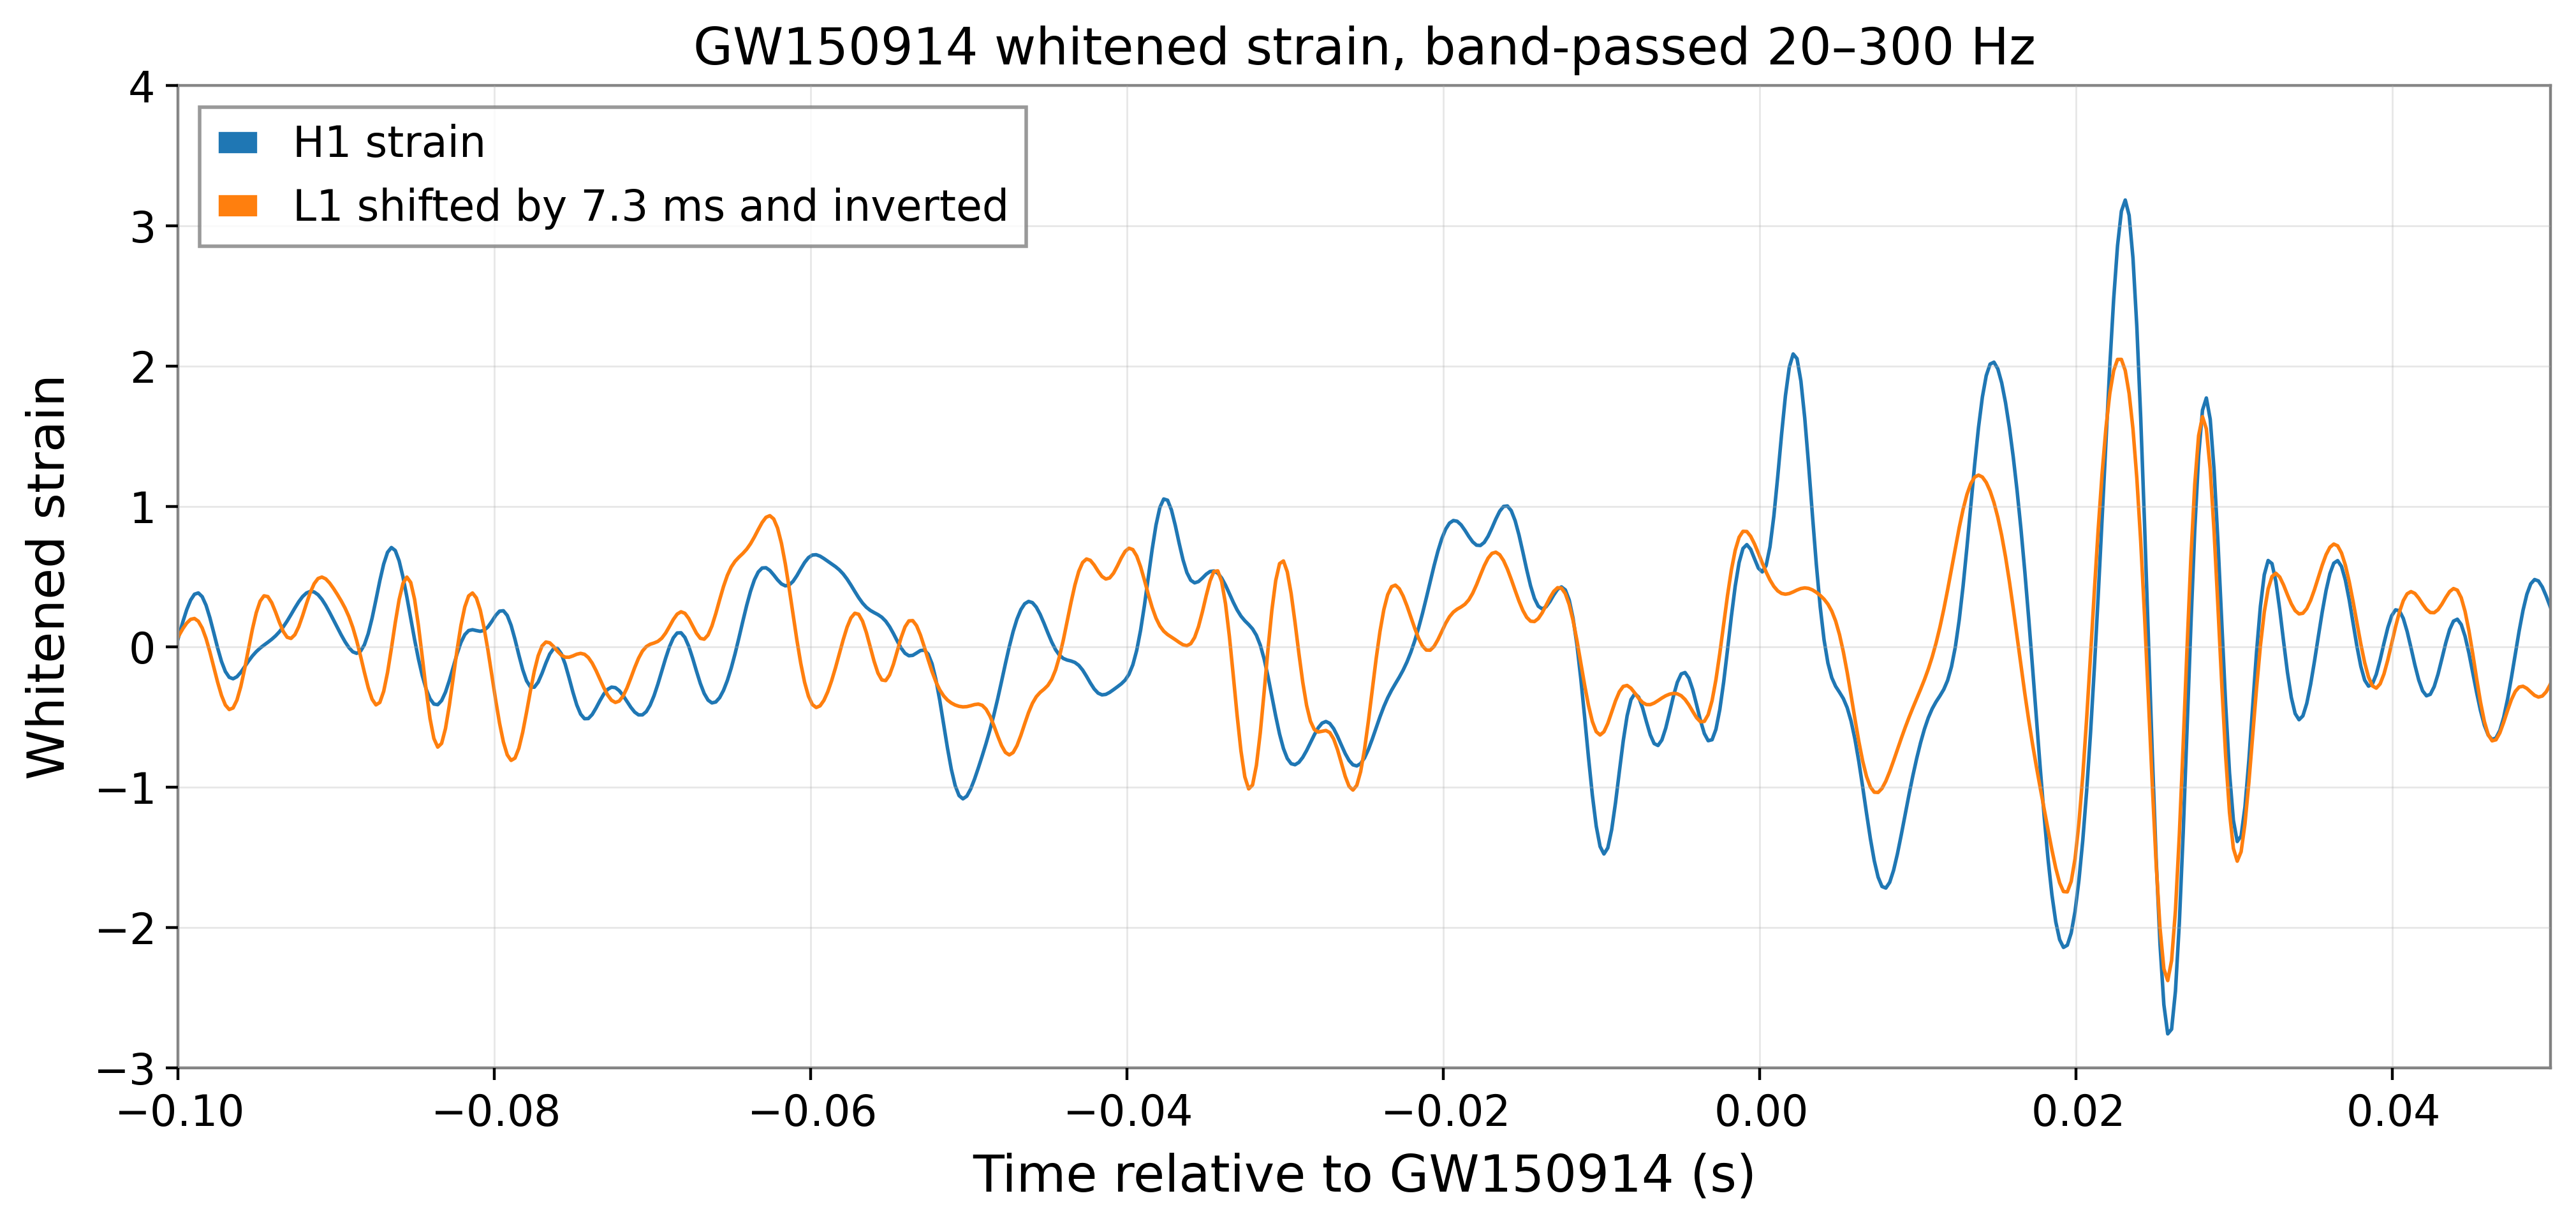

In [10]:
# Livingston arrived about 7 ms earlier;
# shift it for visual comparison and invert its sign
shift_samples = int(0.0073 * fs)
strain_L1_shift = -np.roll(strain_L1_whitenbp, shift_samples)

plt.figure(figsize=(12, 5), dpi = 400)
plt.plot(time_relative, strain_H1_whitenbp, label="H1 strain", linewidth=1)
plt.plot(time_relative, strain_L1_shift, label="L1 shifted by 7.3 ms and inverted", linewidth=1)
plt.xlim(-0.10, 0.05)
plt.ylim(-3, 4)
plt.xlabel("Time relative to GW150914 (s)")
plt.ylabel("Whitened strain")
plt.title("GW150914 whitened strain, band-passed 20–300 Hz")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

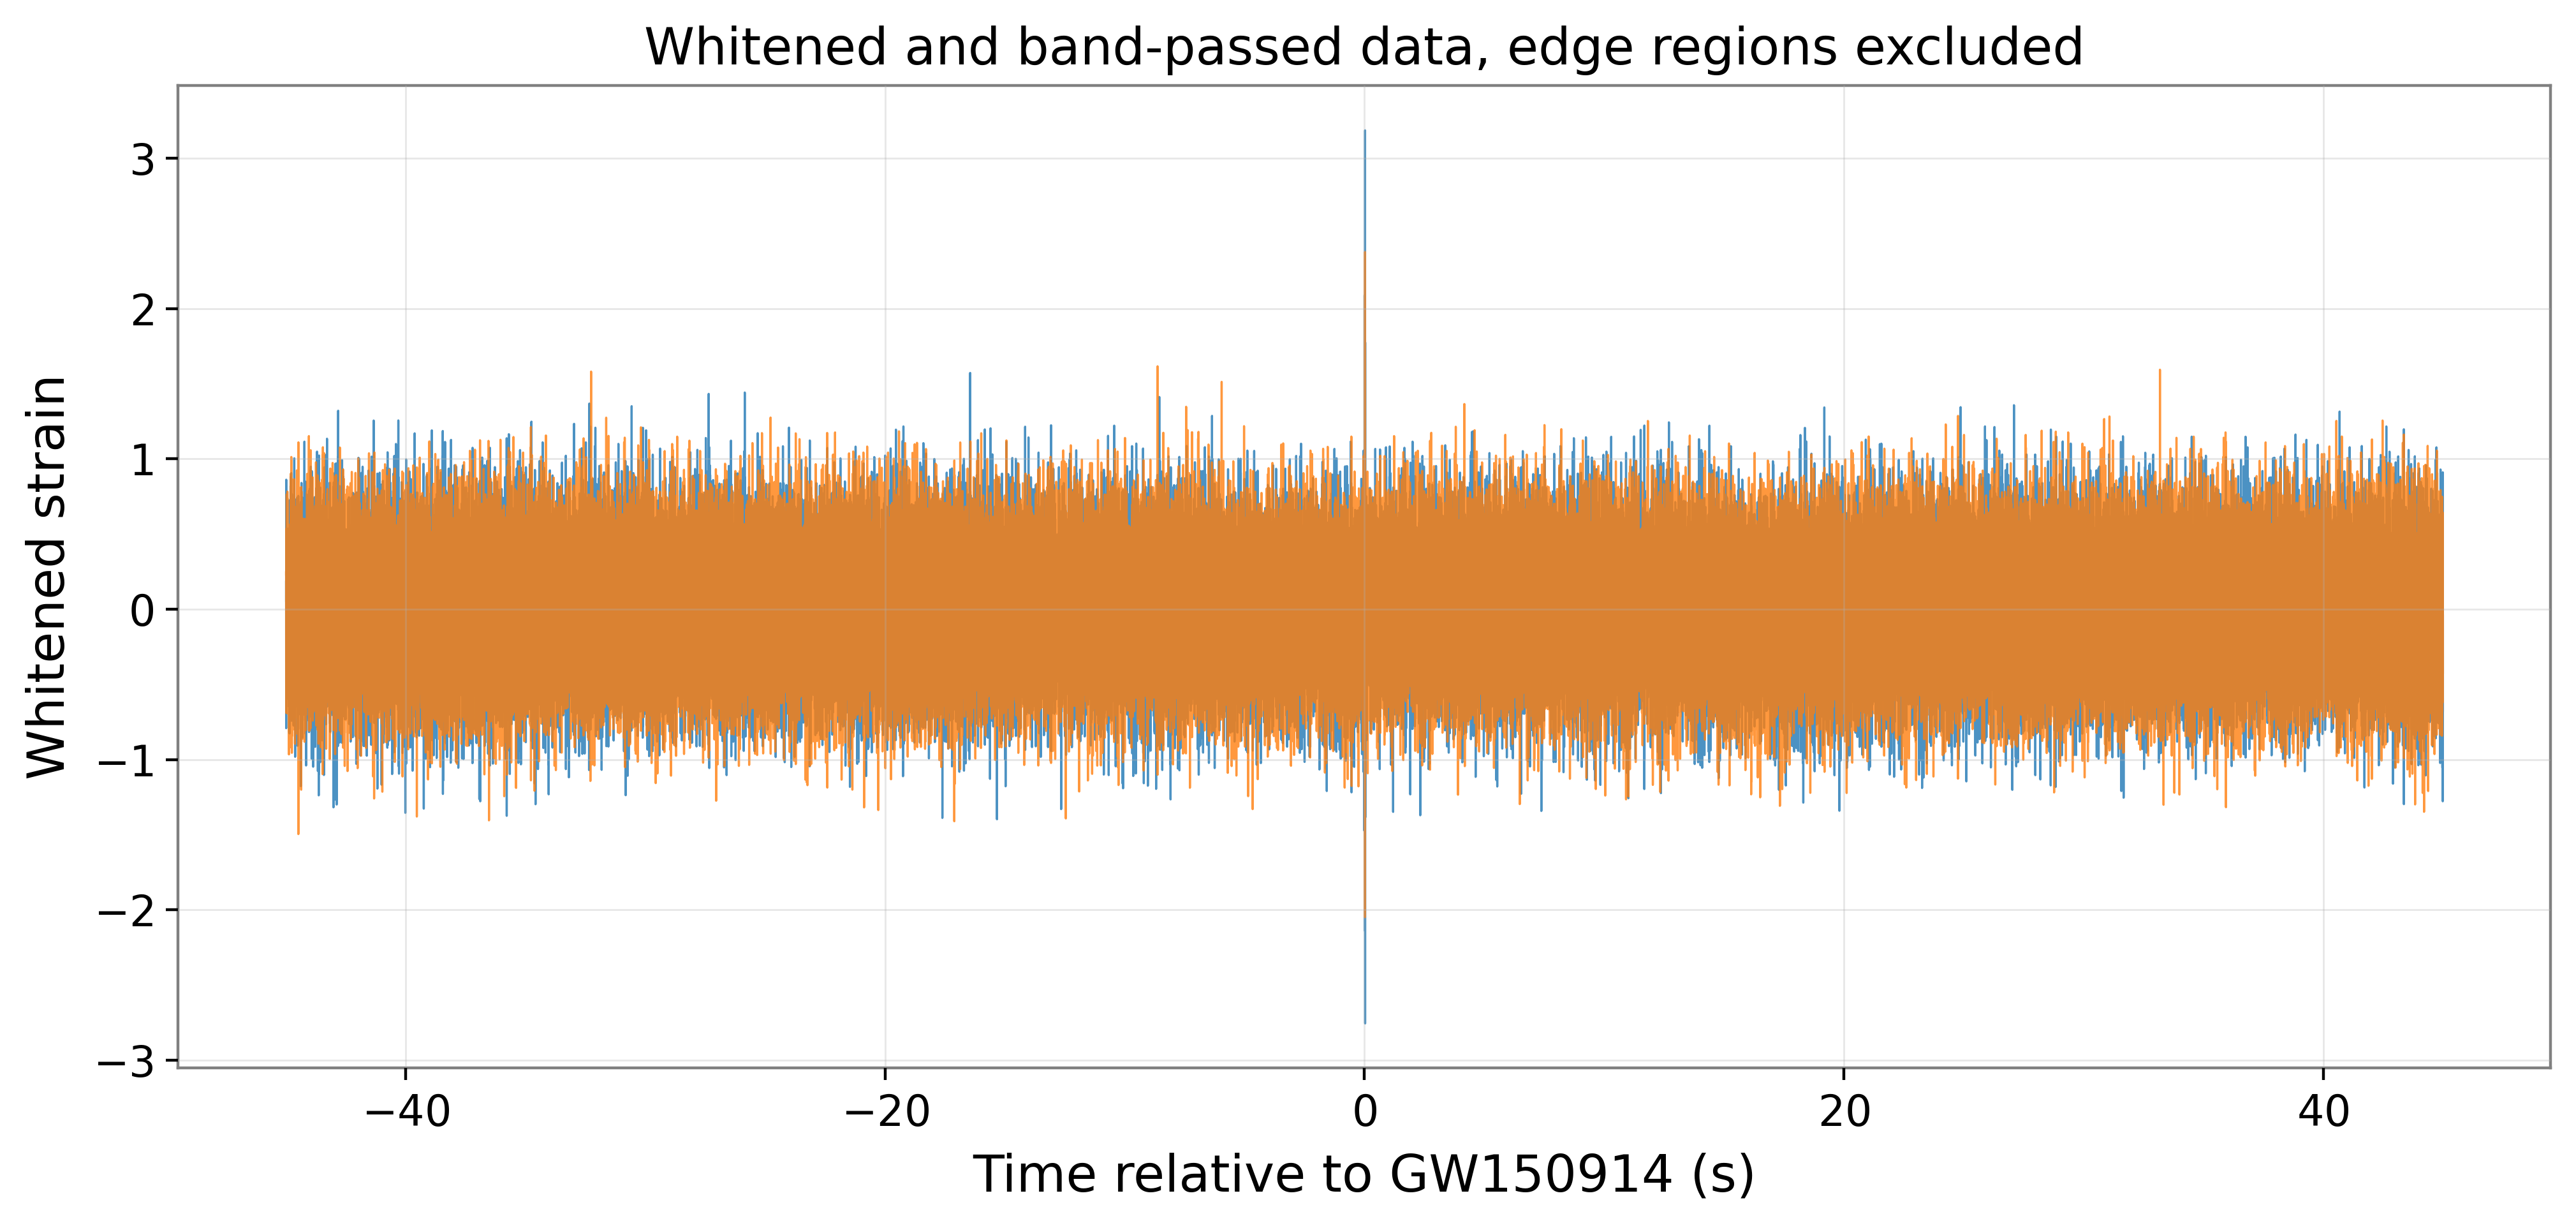

In [11]:
valid_mask = ((time_relative >= -45) & (time_relative <= 45))

plt.figure(figsize=(12, 5), dpi = 400)
plt.plot(time_relative[valid_mask], strain_H1_whitenbp[valid_mask], label="H1", linewidth=0.6, alpha=0.8)
plt.plot(time_relative[valid_mask], strain_L1_whitenbp[valid_mask], label="L1", linewidth=0.6, alpha=0.8)
plt.xlabel("Time relative to GW150914 (s)")
plt.ylabel("Whitened strain")
plt.title("Whitened and band-passed data, edge regions excluded")
plt.grid(True, alpha=0.3)
plt.show()

In [12]:
# Simple dot-product correlation between two arrays.
def cc(x, y):
    correlation = sum(a * b for a, b in zip(x, y))
    return correlation
    
# Cross-correlate two real detector data segments.
# data1: H1 segment
# data2: L1 segment
# times: time array for that segment

def cross_correlation_real_detector(data1, data2, times):
    data1 = data1 - np.mean(data1)
    data2 = data2 - np.mean(data2)

    correlations = []

    # Define lag range
    lags = np.arange(-len(times)//2, len(times)//2, 1)

    for lag in lags:
        data1_shifted = np.roll(data1, int(lag))

        correlation = cc(data1_shifted, data2)

        # Normalize by segment length
        correlation = correlation / len(times)

        correlations.append(correlation)

    correlations = np.array(correlations)

    return correlations, lags

In [13]:
# Remove first and last 2 seconds from 104 s data
# Then split the remaining 100 s into 100 one-second segments

num_files = 100

segment_duration = 1  # second
segment_samples = int(fs * segment_duration)  # 4096 samples

trim_duration = 2  # remove 2 seconds from both sides
trim_samples = int(fs * trim_duration)  # 8192 samples


# Keep only the middle 100 seconds
strain_H1_middle = strain_H1_whitenbp[trim_samples : trim_samples + num_files * segment_samples]
strain_L1_middle = strain_L1_whitenbp[trim_samples : trim_samples + num_files * segment_samples]

print("H1 middle-data shape:", strain_H1_middle.shape)
print("L1 middle-data shape:", strain_L1_middle.shape)

# Split middle 100 s into 100 one-second segments
h1_segments = []
l1_segments = []

for i in range(num_files):

    start_idx = i * segment_samples
    end_idx = start_idx + segment_samples

    h1_seg = strain_H1_middle[start_idx:end_idx]
    l1_seg = strain_L1_middle[start_idx:end_idx]

    h1_segments.append(h1_seg)
    l1_segments.append(l1_seg)


# Convert lists into NumPy arrays
h1_segments = np.array(h1_segments)
l1_segments = np.array(l1_segments)

print("H1 segments shape:", h1_segments.shape)
print("L1 segments shape:", l1_segments.shape)

H1 middle-data shape: (409600,)
L1 middle-data shape: (409600,)
H1 segments shape: (100, 4096)
L1 segments shape: (100, 4096)


In [14]:
# Time array for one segment
times = np.arange(segment_samples) / fs

print("Time array shape:", times.shape)
print("Start time:", times[0])
print("End time:", times[-1])

Time array shape: (4096,)
Start time: 0.0
End time: 0.999755859375


In [16]:
# Build 100 GW_real test files + labels using real GW150914 data

save_folder = "../TranAD_MGB/data/GW150914/test/"
label_folder = "../TranAD_MGB/data/GW150914/labels/"

os.makedirs(save_folder, exist_ok=True)
os.makedirs(label_folder, exist_ok=True)

num_files = 100
segment_samples = 4096       # 1 second at 4096 Hz
section_samples = 1024       # 1 second split into 4 parts
fs = int(fs)

# Locate GW150914 inside the 100-second stream

tevent_gps = event_gps("GW150914")
start_gps = int(tevent_gps) - 50    # segment = (int(tevent_gps) - 50, int(tevent_gps) + 50)
event_time_in_segment = tevent_gps - start_gps
signal_file_index = int(event_time_in_segment) # Which 1-second file contains the event?
event_position_in_file = int((event_time_in_segment - signal_file_index) * fs) # Position of event inside that 1-second file
event_section_index = event_position_in_file // section_samples # Which 1024-sample section contains the event?
label_start = event_section_index * section_samples
label_end = label_start + section_samples

print("Event GPS:", tevent_gps)
print("Start GPS:", start_gps)
print("Event time inside 100 s stream:", event_time_in_segment, "s")
print("Signal file index:", signal_file_index)
print("Event position inside file:", event_position_in_file)
print("Event section:", event_section_index + 1)
print("Label region:", label_start, "to", label_end)

# Generate cross-correlation test files and labels
maxccs = []

for i in range(num_files):

    # Take one 1-second H1 and L1 segment
    noise1 = h1_segments[i]
    noise2 = l1_segments[i]

    # Remove mean
    noise1 = noise1 - np.mean(noise1)
    noise2 = noise2 - np.mean(noise2)

    # Split each 1-second file into 4 sections
    noise1_sec1 = noise1[0:1024]
    noise1_sec2 = noise1[1024:2048]
    noise1_sec3 = noise1[2048:3072]
    noise1_sec4 = noise1[3072:4096]

    noise2_sec1 = noise2[0:1024]
    noise2_sec2 = noise2[1024:2048]
    noise2_sec3 = noise2[2048:3072]
    noise2_sec4 = noise2[3072:4096]

    # Time array for each 1024-sample section
    times_sec = np.arange(0, 1024) / fs

    # Cross-correlation for each section
    ccnoise1, lags1 = cross_correlation_real_detector(noise1_sec1, noise2_sec1, times_sec)
    ccnoise2, lags2 = cross_correlation_real_detector(noise1_sec2, noise2_sec2, times_sec)
    ccnoise3, lags3 = cross_correlation_real_detector(noise1_sec3, noise2_sec3, times_sec)
    ccnoise4, lags4 = cross_correlation_real_detector(noise1_sec4, noise2_sec4, times_sec)

    # Combine 4 sections into one 4096-sample file
    final_sig = np.concatenate((ccnoise1, ccnoise2, ccnoise3, ccnoise4))

    # Create label array
    label = np.zeros(len(final_sig))

    # Only the signal-containing file gets label = 1
    if i == signal_file_index:
        label[label_start:label_end] = 1

    # Store maximum cross-correlation
    maxcc = np.max(np.abs(final_sig))
    maxccs.append(maxcc)
    
    # Save files
    filename = str(i) + "_GW150914_test.txt"
    labelname = str(i) + "_GW150914_labels.txt"

    np.savetxt(os.path.join(save_folder, filename), final_sig)
    np.savetxt(os.path.join(label_folder, labelname), label)

    print("saved test file", i)

maxccs = np.array(maxccs)
print("Done.")

Event GPS: 1126259462.4
Start GPS: 1126259412
Event time inside 100 s stream: 50.40000009536743 s
Signal file index: 50
Event position inside file: 1638
Event section: 2
Label region: 1024 to 2048
saved test file 0
saved test file 1
saved test file 2
saved test file 3
saved test file 4
saved test file 5
saved test file 6
saved test file 7
saved test file 8
saved test file 9
saved test file 10
saved test file 11
saved test file 12
saved test file 13
saved test file 14
saved test file 15
saved test file 16
saved test file 17
saved test file 18
saved test file 19
saved test file 20
saved test file 21
saved test file 22
saved test file 23
saved test file 24
saved test file 25
saved test file 26
saved test file 27
saved test file 28
saved test file 29
saved test file 30
saved test file 31
saved test file 32
saved test file 33
saved test file 34
saved test file 35
saved test file 36
saved test file 37
saved test file 38
saved test file 39
saved test file 40
saved test file 41
saved test file

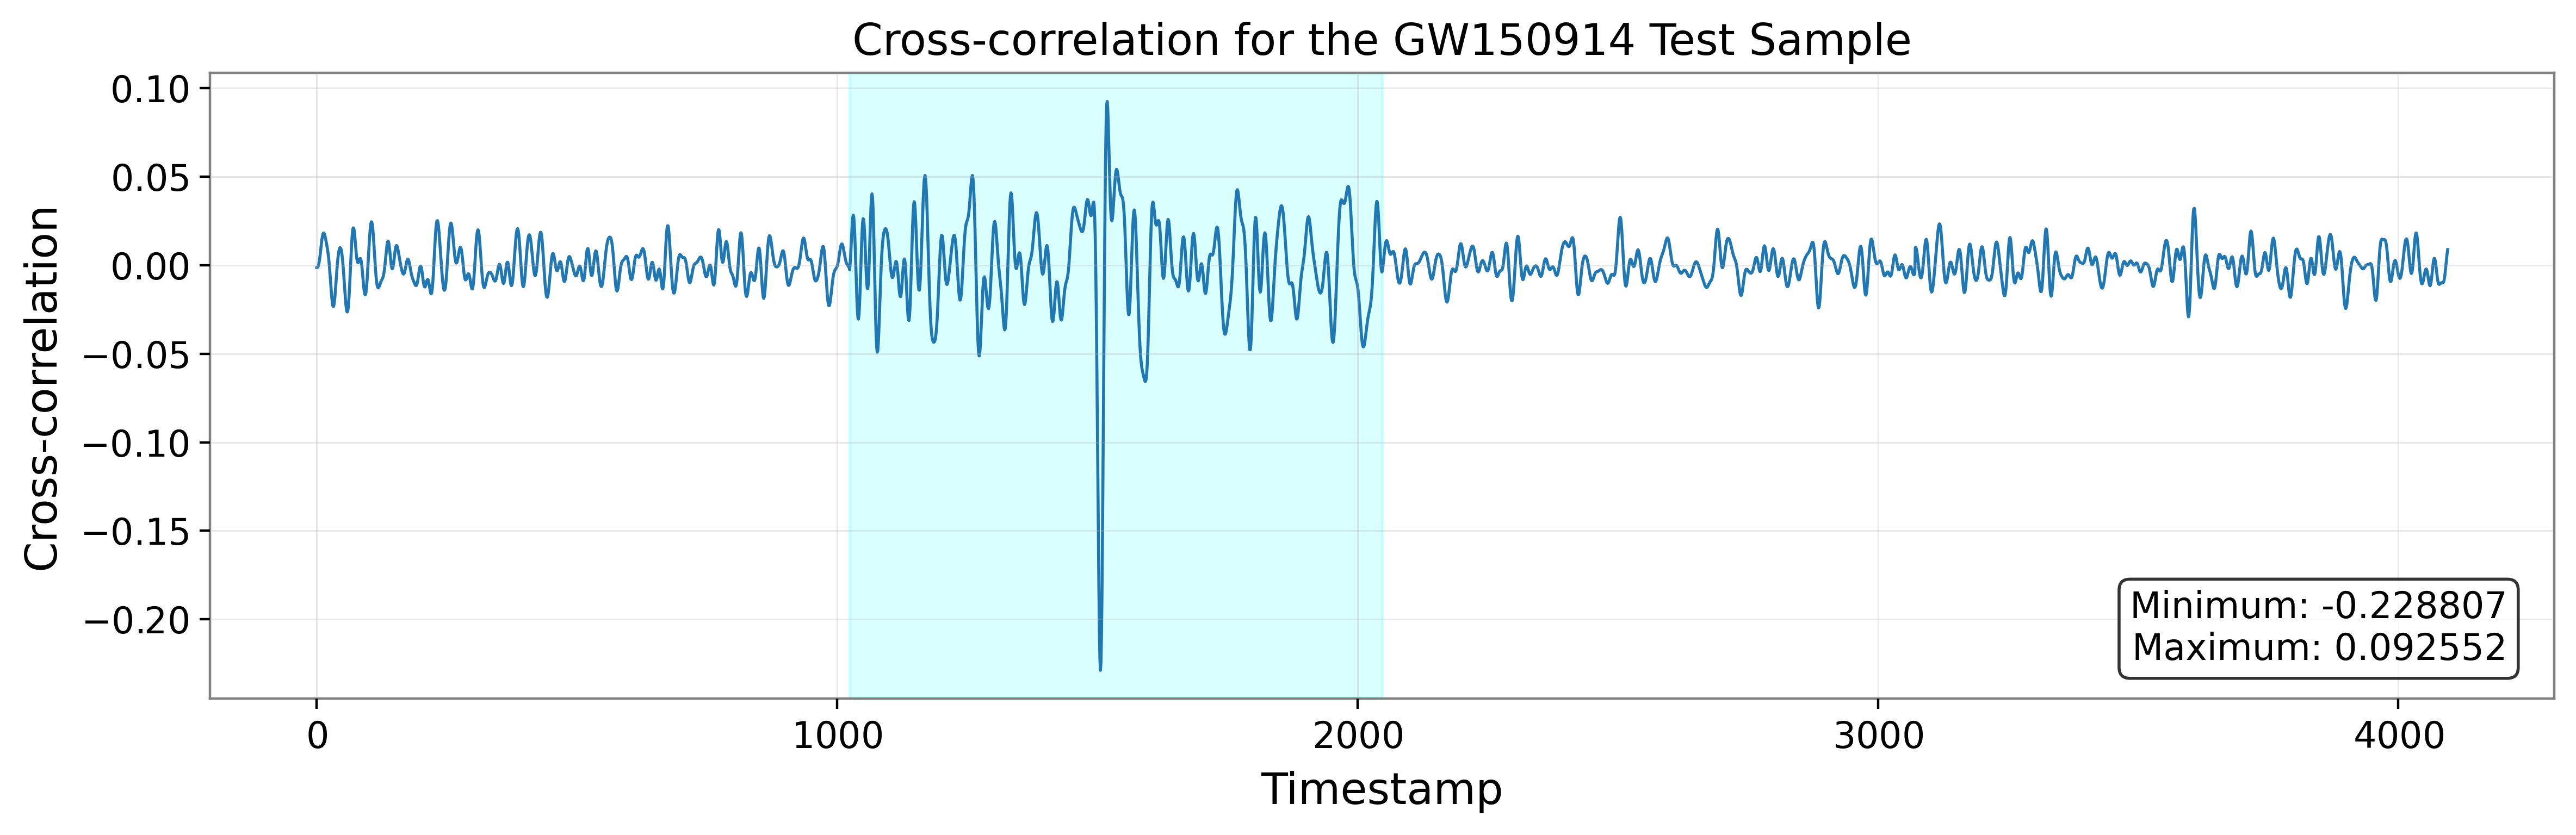

In [17]:
sample = np.loadtxt(os.path.join(save_folder, str(signal_file_index)+ "_GW150914_test.txt"))
x = np.arange(len(sample))

# Calculate minimum and maximum values
min_value = sample.min()
max_value = sample.max()

plt.figure(figsize=(12, 4), dpi=400)
plt.plot(x, sample, linewidth=1.0)

plt.xlabel("Timestamp")
plt.ylabel("Cross-correlation")
plt.title("Cross-correlation for the GW150914 Test Sample")

# Highlight signal region
plt.axvspan(
    1024,
    2048,
    color="cyan",
    alpha=0.15,
    label="Signal-containing region"
)

# Display minimum and maximum values at the bottom-right
plt.text(
    0.98,
    0.05,
    f"Minimum: {min_value:.6f}\nMaximum: {max_value:.6f}",
    transform=plt.gca().transAxes,
    horizontalalignment="right",
    verticalalignment="bottom",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.8
    )
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
#plt.savefig("GW150914_correlation.png", dpi = 400, bbox_inches = "tight")
plt.show()